#### Out-of-Distribution Detection

##### Importing Libraries and Loading Data

In [6]:
# Libraries; the classifier and risk model exactly as served

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.metrics import roc_auc_score

from planscope.category_data import OUT_DIR
from planscope.classifier import CategoryClassifier
from planscope.fill_categories import MODEL_DIR
from planscope.outcome_model import OUT_PATH as RISK_PATH
from planscope.risk import TOKEN, RiskModel, prepare

classifier = CategoryClassifier(MODEL_DIR)
risk = RiskModel(RISK_PATH)

In [7]:
# In-distribution: 10,000 held-out test descriptions the classifier never trained on

real = pd.read_parquet(OUT_DIR / 'test.parquet').sample(10_000, random_state=0)['text'].tolist()

In [8]:
# Far: 500 strings of random letters, shaped like short descriptions (3-12 'words' of 2-9 letters)

rng = np.random.default_rng(0)
letters = list('abcdefghijklmnopqrstuvwxyz')
gibberish = [' '.join(''.join(rng.choice(letters, rng.integers(2, 10))) for _ in range(rng.integers(3, 13))) for _ in range(500)]
gibberish[:3]

['nhibbae qxnpzsqo yhvrak oatswecw oc mkka da nqgqtjl uzjryqvrs wdpsv jikmsx',
 'njrogispn tkix fsqb',
 'vkuig wcbriodw xusft']

In [9]:
# Medium: 500 news snippets, fluent English about other topics (AG News test split)

news = list(load_dataset('fancyzhx/ag_news', split='test').shuffle(seed=0).select(range(500))['text'])
news[:2]

['McTeer: Lonesome Dove to be an Aggie NEW YORK (CNN/Money) - A New Economy champion, a lover of the Texas picker poets who write lovesick country songs...and, oh, by the way, a member of the Federal Reserve system for 36 years.',
 "Peru Gov't: Police Killed in Self-Defense Peru's interior minister said Wednesday that police acted in self-defense when they killed three coca farmers who were part of a group that hurled rocks and tried to burn a police lieutenant alive to protest U.S.-backed eradication of their cocaine producing crop."]

##### Familiarity Scores

In [10]:
# Three scores per text; for each, higher means more like a real planning description

def coverage(text):
    '''Share of the words the risk model has seen in past applications (0 when there are no words).'''
    words = TOKEN.findall(prepare(text))
    return np.mean([word in risk.index for word in words]) if words else 0.0


def scores(texts):
    logits = np.vstack([classifier.logits([text]) for text in texts])  # one text at a time, as the API runs
    top = logits.max(axis=1)
    total = np.exp(logits - top[:, None]).sum(axis=1)
    return pd.DataFrame({
        'text': texts,
        'softmax': 1 / total,  # the top category's probability
        'energy': top + np.log(total),  # logsumexp of the logits
        'coverage': [coverage(text) for text in texts],
    })


sets = {'real': real, 'gibberish': gibberish, 'news': news}
scored = pd.concat([scores(texts).assign(set=name) for name, texts in sets.items()], ignore_index=True)
scored.groupby('set')[['softmax', 'energy', 'coverage']].median().round(3)

,softmax,energy,coverage
set,,,
gibberish,0.566,2.563,0.000
news,0.473,1.989,0.714
real,0.987,6.078,1.000


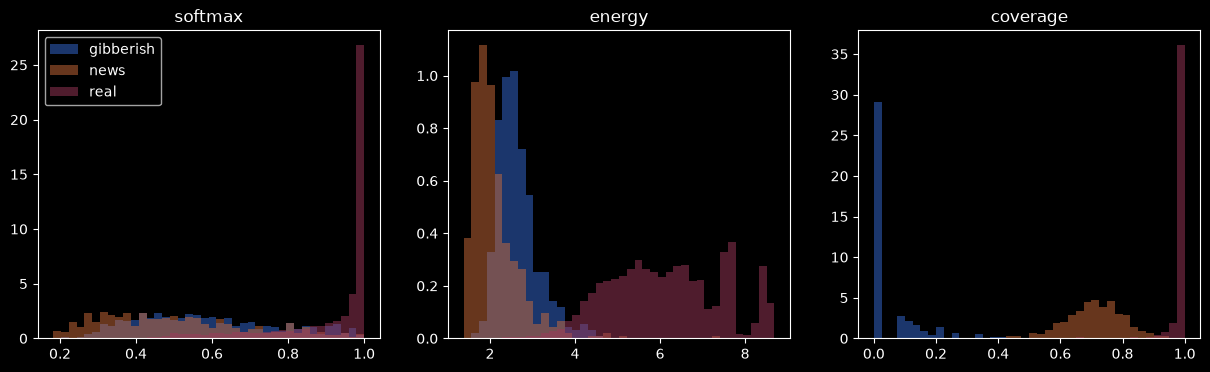

In [11]:
# Each score's distribution by set: the less a set overlaps with 'real', the easier it is to catch

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, signal in zip(axes, ['softmax', 'energy', 'coverage']):
    bins = np.linspace(scored[signal].min(), scored[signal].max(), 41)
    for name, group in scored.groupby('set'):
        ax.hist(group[signal], bins=bins, density=True, alpha=0.5, label=name)
    ax.set_title(signal)
axes[0].legend()
plt.show()

##### How Well Each Score Separates Real from Off-Topic

In [12]:
# AUROC: chance a real description scores above an off-topic text (1 = perfect, 0.5 = guessing)
# FPR@95: share of off-topic texts let through when 95% of real descriptions are (0 = perfect)

def separation(signal, ood):
    real_scores = scored.loc[scored['set'] == 'real', signal]
    ood_scores = scored.loc[scored['set'] == ood, signal]
    labels = np.r_[np.ones(len(real_scores)), np.zeros(len(ood_scores))]
    return {'auroc': roc_auc_score(labels, np.r_[real_scores, ood_scores]),
            'fpr@95': (ood_scores >= real_scores.quantile(0.05)).mean()}


pd.DataFrame({(signal, ood): separation(signal, ood) for signal in ['softmax', 'energy', 'coverage']
              for ood in ['gibberish', 'news']}).T.unstack().round(3)

auroc           fpr@95       
         gibberish   news gibberish   news
coverage     0.999  0.993     0.000  0.000
energy       0.995  0.996     0.018  0.012
softmax      0.915  0.945     0.478  0.316

##### A Rule to Ship

In [13]:
# Flag a text if either score is below what 99.5% of real descriptions reach, so at most about 1% of real ones are flagged

thresholds = scored.loc[scored['set'] == 'real', ['energy', 'coverage']].quantile(0.005)
scored['flagged'] = (scored['energy'] < thresholds['energy']) | (scored['coverage'] < thresholds['coverage'])
print(thresholds.round(3).to_dict())
scored.groupby('set')['flagged'].mean().round(3)

{'energy': 3.113, 'coverage': 0.667}


set
gibberish    1.000
news         0.960
real         0.008
Name: flagged, dtype: float64

In [14]:
# What the rule gets wrong: real descriptions it flags, and news snippets it lets through

pd.set_option('display.max_colwidth', 110)
cols = ['text', 'energy', 'coverage']
pd.concat({'real but flagged': scored[(scored['set'] == 'real') & scored['flagged']].head(5)[cols],
           'news but passed': scored[(scored['set'] == 'news') & ~scored['flagged']].head(5)[cols]})

text  \
real but flagged 59           removal of the existing pea shingle pathways and relaying with self binding gravel (breedon amber gold)   
                 357                                                                                            25 hilda road e16 4nw   
                 399                                                                                  fl370_37 charteris road, n4 3aa   
                 588                                                                              please refer to the covering letter   
                 761    division of the existing plot of land at 44 valentine avenue bexley kent da5 3he to introduce a additional...   
news but passed  10517  Israel to present PA with  #39;good will #39; steps in coming days Israel will respond with a series of po...   
                 10557  Thai Airways orders six Airbus superjumbos Thai Airways International plans to buy six Airbus A380 double-...   
                 10647  Dream TV Screen, Now in Size Large The most desired electronic gift item for this holiday season is a plas...   
                 10650  Virgin to Launch Commercial Space Flights by 2007 SEPTEMBER 28, 2004 -- London -- The ultimate high-end in...   
                 10662  Times to go completely compact The Times newspaper has announced that it is to move on from its tradition ...   

                          energy  coverage  
real but flagged 59     2.652063  0.937500  
                 357    3.875896  0.600000  
                 399    2.982368  0.400000  
                 588    2.485275  1.000000  
                 761    3.078225  0.857143  
news but passed  10517  3.206945  0.750000  
                 10557  3.600518  0.771429  
                 10647  4.807498  0.939394  
                 10650  3.242309  0.833333  
                 10662  3.339780  0.852941

In [15]:
# Does each check earn its place? Each score alone at a 1% false-alarm rate, against the rule (two 0.5% checks)

real_scores = scored.loc[scored['set'] == 'real']
checks = pd.DataFrame({signal: scored[signal] < real_scores[signal].quantile(0.01) for signal in ['energy', 'coverage']})
checks['rule'] = scored['flagged']
checks.groupby(scored['set']).mean().round(3)

,energy,coverage,rule
set,,,
gibberish,0.926,1.000,1.000
news,0.964,0.844,0.960
real,0.010,0.009,0.008


##### Findings and Decisions
- **Question:** can the API tell when a description isn't a planning application, so the page doesn't give a confident answer for nonsense?
- **Data:** 10,000 held-out test descriptions (real) against 500 random-letter strings (gibberish) and 500 AG News snippets (fluent English on other topics).
- **Scores:** the classifier's top probability (max softmax, the usual baseline), energy (logsumexp of its logits) and word coverage (share of words in the risk model's vocabulary).

| Score | AUROC gibberish | AUROC news | FPR@95 gibberish | FPR@95 news |
|---|---|---|---|---|
| Max softmax | 0.915 | 0.945 | 0.478 | 0.316 |
| Energy | 0.995 | 0.996 | 0.018 | 0.012 |
| Word coverage | 0.999 | 0.993 | 0.000 | 0.000 |

- **Softmax is a poor detector here:** keeping 95% of real descriptions, it lets through 48% of gibberish and 32% of news. Real descriptions often split their probability between legal routes (notebook 02: a text-only ceiling of about 91%), so a low top probability means "ambiguous" as often as "unfamiliar". Energy keeps the logits' overall size, which softmax discards: ambiguous real text still has large logits, off-topic text has small ones (medians 6.08 real, 2.56 gibberish, 1.99 news).
- **Rule:** flag a text if energy < 3.113 or coverage < 0.667, each the level 99.5% of real descriptions reach. It flags 100% of gibberish, 96.0% of news and 0.8% of real descriptions.
- **Ablation (each score alone at a 1% false-alarm budget):** energy flags 92.6% of gibberish and 96.4% of news (1.0% of real); coverage flags 100% and 84.4% (0.9% of real). They fail on different texts: coverage catches every random string, energy catches fluent off-topic English. Together they flag 100% and 96.0% with the fewest false alarms (0.8%), so both stay; energy's 96.4% on news is within the noise of 500 texts.
- **False alarms:** of the first five real descriptions flagged, three are not descriptions at all (a bare address, a reference code with an address, "please refer to the covering letter"); two are real but unusually worded (self-binding gravel paths, a plot division with a full address).
- **Misses:** news that passed is about orders, launches and plans, and shares planning-like words (coverage 0.75–0.94).
- **Limitations:** no near-domain set (housing text that is not a planning application); 500 texts per set gives flagged rates about ±2 points. Fluent but absurd applications ("a moat filled with crocodiles") are not out of distribution: they read like householder applications, and judging sense is not this model's job.
- **Decision:** serve the rule as a `familiar` flag on /classify and /predict, and show "This doesn't look like a planning application description" instead of a result. It replaces the page's "few of these words" warning, whose `words_known < 3` condition also fires on short real descriptions such as "rear dormer".